# EV Charging Network — Session Anomaly Detection (Analysis 11)

## 1. Business Problem & Executive Summary
In a large-scale commercial and public EV charging network operating 33 stations, 199 chargers, and over 294,000 charging sessions across 2022–2024, maintaining infrastructure reliability, billing integrity, and operational safety requires automated detection of unusual charging events.

### Defining An Anomaly in EV Charging:
An **anomaly** is an observation that deviates significantly from the central tendency and multivariate correlation structure of standard charging behavior. 
Crucially:
- **An anomaly is NOT automatically a confirmed fault, fraud event, or defective hardware.**
- Anomalies encompass:
  1. *Physical & Electrical Deviations*: Abnormally low power draw on ultra-rapid chargers (potential battery thermal throttling or onboard BMS limitation), or unexpected dwell times.
  2. *Commercial & Billing Outliers*: Tariff edge cases, extreme session spend, or tariff mismatches.
  3. *Operational Behavioral Shifts*: Off-peak fleet usage patterns, high-frequency short-dwell bursts, or station-specific throughput distortions.
  4. *Data Capture Discrepancies*: Truncated metering or sensor timing artifacts.

### Analytical Objectives:
1. Establish univariate and multivariate **statistical outlier baselines** (IQR and Z-score).
2. Implement and evaluate **unsupervised machine learning models**:
   - **Isolation Forest**: Tree-based recursive partitioning isolating anomalies in sparse regions.
   - **Neural Autoencoder**: Multi-Layer Perceptron (MLP) encoder-decoder network (16 -> 4 -> 16) trained to reconstruct normal multivariate charging patterns, flagging sessions with high mean squared reconstruction error (MSE).
3. Systematically compare model concordance, score distributions, and detection characteristics.
4. Conduct deep-dive root cause categorizations across charger types, user types, and station locations.
5. Provide actionable operational frameworks for triage queues, maintenance dispatch, and billing verification.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from scipy import stats
import os
import warnings

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Load raw datasets
data_path = os.path.join('..', '..', 'data', 'raw', 'ev_charging_dataset.xlsx')
sessions = pd.read_excel(data_path, sheet_name='sessions')
stations = pd.read_excel(data_path, sheet_name='stations')
chargers = pd.read_excel(data_path, sheet_name='chargers')

print("Loaded raw dataset:")
print(f" - Sessions: {len(sessions):,} records, {sessions.shape[1]} columns")
print(f" - Stations: {len(stations):,} records")
print(f" - Chargers: {len(chargers):,} records")


Loaded raw dataset:
 - Sessions: 294,024 records, 15 columns
 - Stations: 33 records
 - Chargers: 199 records


## 2. Data Validation & Preprocessing Audit

Before feature engineering, we audit data types, missingness, duplicates, and range boundaries:
- Ensure 0 missing values and 0 duplicate session IDs.
- Parse timestamps into datetime objects.
- Merge charger technical specifications (`max_power_kW`) from the `chargers` sheet.


In [2]:
# Check missing and duplicates
missing_count = sessions.isnull().sum().sum()
duplicate_count = sessions.duplicated(subset=['session_id']).sum()

print(f"Total missing values: {missing_count}")
print(f"Duplicate session IDs: {duplicate_count}")

# Timestamp formatting
sessions['start_timestamp'] = pd.to_datetime(sessions['start_timestamp'])
sessions['end_timestamp'] = pd.to_datetime(sessions['end_timestamp'])

# Merge charger technical specifications
sessions = sessions.merge(chargers[['charger_id', 'max_power_kW']], on='charger_id', how='left')

# Verify merge integrity
assert sessions['max_power_kW'].isnull().sum() == 0, "Missing charger specification matches!"
print(f"Successfully linked charger technical specifications across all {len(sessions):,} sessions.")
display(sessions[['session_id', 'charger_id', 'charger_type', 'max_power_kW', 'energy_kwh', 'session_duration_minutes', 'total_cost']].head())


Total missing values: 0
Duplicate session IDs: 0
Successfully linked charger technical specifications across all 294,024 sessions.
   session_id     charger_id  ... session_duration_minutes  total_cost
0  S_00000001  STN_001_CH_02  ...                       26       26.74
1  S_00000002  STN_001_CH_02  ...                       21       18.72
2  S_00000003  STN_001_CH_04  ...                       48       14.52
3  S_00000004  STN_001_CH_01  ...                       41       12.78
4  S_00000005  STN_001_CH_01  ...                       50       17.75

[5 rows x 7 columns]


## 3. Exploratory Data Analysis: Operational Distributions

We investigate key continuous metrics to identify standard operating distributions vs. extreme boundaries:
- Delivered energy (kWh), duration (minutes), total cost (£), and price (£/kWh).
- Average charging power (kW): Avg Power = (energy_kwh / session_duration_minutes) * 60.
- Power utilization ratio: Utilization = Avg Power (kW) / max_power_kW.


In [3]:
# Derive operational engineering metrics
sessions['avg_power_kw'] = (sessions['energy_kwh'] / sessions['session_duration_minutes']) * 60
sessions['power_utilization_ratio'] = sessions['avg_power_kw'] / sessions['max_power_kW']
sessions['cost_per_minute'] = sessions['total_cost'] / sessions['session_duration_minutes']
sessions['hour'] = sessions['start_timestamp'].dt.hour
sessions['day_of_week'] = sessions['start_timestamp'].dt.dayofweek

eda_cols = ['energy_kwh', 'session_duration_minutes', 'avg_power_kw', 'power_utilization_ratio', 'price_per_kwh', 'total_cost', 'cost_per_minute']
eda_summary = sessions[eda_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
eda_summary['IQR'] = eda_summary['75%'] - eda_summary['25%']

print("--- OPERATIONAL METRICS DISTRIBUTION ---")
display(eda_summary.round(3))


--- OPERATIONAL METRICS DISTRIBUTION ---
                             mean     std     min  ...      75%      max     IQR
energy_kwh                 46.965  16.632  21.700  ...   54.000   80.000  20.800
session_duration_minutes   35.095  13.780  15.000  ...   49.000   60.000  26.000
avg_power_kw              105.930  73.924  32.444  ...  128.160  270.000  87.925
power_utilization_ratio     0.795   0.049   0.640  ...    0.829    0.901   0.068
price_per_kwh               0.592   0.064   0.450  ...    0.640    0.800   0.100
total_cost                 27.791  10.269  11.450  ...   33.250   64.000  13.550
cost_per_minute             1.044   0.739   0.248  ...    1.346    3.511   0.947

[7 rows x 8 columns]


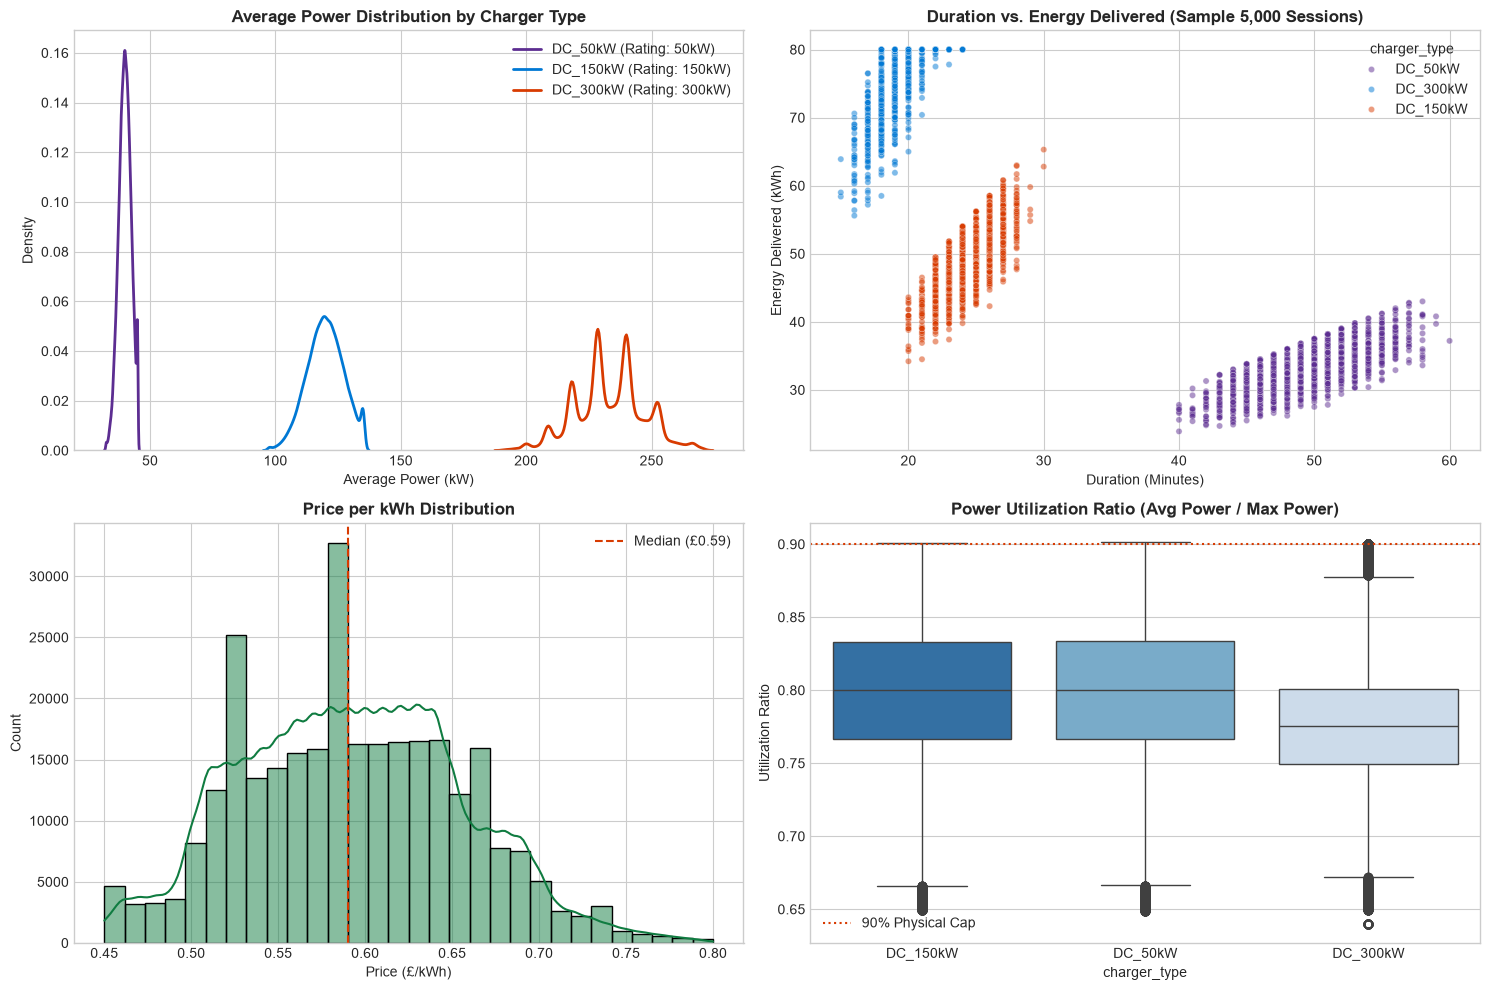

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Avg Power Distribution by Charger Type
for ctype, col in zip(['DC_50kW', 'DC_150kW', 'DC_300kW'], ['#5C2D91', '#0078D4', '#D83B01']):
    sub = sessions[sessions['charger_type'] == ctype]
    sns.kdeplot(sub['avg_power_kw'], label=f"{ctype} (Rating: {sub['max_power_kW'].iloc[0]}kW)", ax=axes[0, 0], color=col, linewidth=2)
axes[0, 0].set_title('Average Power Distribution by Charger Type', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Average Power (kW)', fontsize=10)
axes[0, 0].legend()

# 2. Duration vs Energy Scatter with Charger Clusters
sns.scatterplot(data=sessions.sample(5000, random_state=42), x='session_duration_minutes', y='energy_kwh',
                hue='charger_type', palette=['#5C2D91', '#0078D4', '#D83B01'], alpha=0.5, s=20, ax=axes[0, 1])
axes[0, 1].set_title('Duration vs. Energy Delivered (Sample 5,000 Sessions)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Duration (Minutes)', fontsize=10)
axes[0, 1].set_ylabel('Energy Delivered (kWh)', fontsize=10)

# 3. Price per kWh Distribution
sns.histplot(sessions['price_per_kwh'], bins=30, kde=True, color='#107C41', ax=axes[1, 0])
axes[1, 0].axvline(sessions['price_per_kwh'].median(), color='#D83B01', linestyle='--', label=f"Median (£{sessions['price_per_kwh'].median():.2f})")
axes[1, 0].set_title('Price per kWh Distribution', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Price (£/kWh)', fontsize=10)
axes[1, 0].legend()

# 4. Power Utilization Ratio
sns.boxplot(data=sessions, x='charger_type', y='power_utilization_ratio', palette='Blues_r', ax=axes[1, 1])
axes[1, 1].axhline(0.90, color='#D83B01', linestyle=':', label='90% Physical Cap')
axes[1, 1].set_title('Power Utilization Ratio (Avg Power / Max Power)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Utilization Ratio', fontsize=10)
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## 4. Feature Engineering for Unsupervised Anomaly Detection

To detect complex multivariate anomalies without label leakage or ID overfitting, we construct a normalized feature representation:
- **Continuous Operational Features**: `energy_kwh`, `session_duration_minutes`, `avg_power_kw`, `power_utilization_ratio`, `price_per_kwh`, `total_cost`, `cost_per_minute`.
- **Cyclical Temporal Encodings**: `hour_sin`, `hour_cos`, `dow_sin`, `dow_cos` capturing continuous temporal proximity.
- **Categorical Encodings**: One-hot indicators for `charger_type` and `user_type`.
- **Standardization**: `StandardScaler` centering all features to mean 0, variance 1.


In [5]:
# Cyclical time encoding
sessions['hour_sin'] = np.sin(2 * np.pi * sessions['hour'] / 24)
sessions['hour_cos'] = np.cos(2 * np.pi * sessions['hour'] / 24)
sessions['dow_sin'] = np.sin(2 * np.pi * sessions['day_of_week'] / 7)
sessions['dow_cos'] = np.cos(2 * np.pi * sessions['day_of_week'] / 7)

# Select continuous & encoded features
feature_cols = [
    'energy_kwh', 'session_duration_minutes', 'avg_power_kw',
    'power_utilization_ratio', 'price_per_kwh', 'total_cost', 'cost_per_minute',
    'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos'
]

# Add one-hot encoded charger_type and user_type
ohe_chg = pd.get_dummies(sessions['charger_type'], prefix='chg', dtype=float)
ohe_usr = pd.get_dummies(sessions['user_type'], prefix='usr', dtype=float)

X_all_features = pd.concat([sessions[feature_cols], ohe_chg, ohe_usr], axis=1)

# Fit StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all_features)

print(f"Constructed feature matrix: {X_scaled.shape[0]:,} rows, {X_scaled.shape[1]} features.")
print("Features included:", list(X_all_features.columns))


Constructed feature matrix: 294,024 rows, 18 features.
Features included: ['energy_kwh', 'session_duration_minutes', 'avg_power_kw', 'power_utilization_ratio', 'price_per_kwh', 'total_cost', 'cost_per_minute', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'chg_DC_150kW', 'chg_DC_300kW', 'chg_DC_50kW', 'usr_delivery', 'usr_fleet', 'usr_public', 'usr_taxi']


## 5. Statistical Baseline Anomaly Detection

We establish traditional statistical outlier baselines for benchmark comparison:
1. **IQR-Based Outlier Rule**: An observation is flagged if it falls outside Q1 - 1.5*IQR or Q3 + 1.5*IQR on key operational metrics.
2. **Z-Score Rule**: An observation is flagged if |Z| > 3.0 on standardized continuous metrics.


In [6]:
# 1. IQR Rule
iqr_flags = pd.Series(False, index=sessions.index)
for col in ['energy_kwh', 'session_duration_minutes', 'avg_power_kw', 'price_per_kwh', 'total_cost']:
    q1 = sessions[col].quantile(0.25)
    q3 = sessions[col].quantile(0.75)
    iqr = q3 - q1
    iqr_outliers = (sessions[col] < (q1 - 1.5 * iqr)) | (sessions[col] > (q3 + 1.5 * iqr))
    iqr_flags = iqr_flags | iqr_outliers

# 2. Z-Score Rule (|Z| > 3.0 on any continuous metric)
z_scores = np.abs(stats.zscore(sessions[['energy_kwh', 'session_duration_minutes', 'avg_power_kw', 'price_per_kwh', 'total_cost']]))
z_flags = (z_scores > 3.0).any(axis=1)

sessions['flag_iqr'] = iqr_flags
sessions['flag_zscore'] = z_flags

print("--- STATISTICAL OUTLIER DETECTION RESULTS ---")
print(f"IQR-flagged sessions:      {iqr_flags.sum():,} ({iqr_flags.sum()/len(sessions)*100:.2f}%)")
print(f"Z-Score-flagged sessions:  {z_flags.sum():,} ({z_flags.sum()/len(sessions)*100:.2f}%)")


--- STATISTICAL OUTLIER DETECTION RESULTS ---
IQR-flagged sessions:      5,727 (1.95%)
Z-Score-flagged sessions:  804 (0.27%)


## 6. Machine Learning Anomaly Detection: Isolation Forest & Neural Autoencoder

We implement and evaluate two advanced unsupervised machine learning architectures:

### 1. Isolation Forest
- **Mechanism**: Builds an ensemble of isolation trees by randomly selecting a feature and split value.
- **Contamination Assumption**: We test contamination rates of 1.0%, 2.5%, and 5.0%, adopting 2.5% as our primary triage baseline.
- **Anomaly Score**: Higher scores represent greater isolation depth and abnormality.

### 2. Neural Autoencoder (MLP Reconstruction Network)
- **Mechanism**: A symmetric neural network architecture (D -> 16 -> 4 -> 16 -> D) trained to compress normal charging interactions into a 4-dimensional latent bottleneck and reconstruct the inputs.
- **Reconstruction Error**: MSE between scaled input and reconstructed output.
- **Thresholding**: Threshold at the 97.5th percentile of reconstruction error (2.5% baseline).


In [7]:
# 1. Fit Isolation Forest across contamination assumptions
iso_contam_levels = [0.010, 0.025, 0.050]
iso_models = {}
iso_preds_dict = {}

for contam in iso_contam_levels:
    iso = IsolationForest(n_estimators=100, contamination=contam, random_state=42, n_jobs=-1)
    preds = iso.fit_predict(X_scaled)
    iso_models[contam] = iso
    iso_preds_dict[contam] = (preds == -1)
    print(f"Isolation Forest (contamination={contam*100:.1f}%): Flagged {iso_preds_dict[contam].sum():,} sessions")

# Primary Isolation Forest model (contamination = 0.025)
sessions['flag_isolation_forest'] = iso_preds_dict[0.025]
sessions['iso_anomaly_score'] = -iso_models[0.025].score_samples(X_scaled)

# 2. Fit Neural Autoencoder (MLPRegressor 16 -> 4 -> 16)
print("Training Neural Autoencoder architecture (16 -> 4 -> 16 bottleneck)...")
autoencoder = MLPRegressor(
    hidden_layer_sizes=(16, 4, 16),
    activation='relu',
    solver='adam',
    max_iter=30,
    batch_size=256,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

# Train on representative sample of 60,000 sessions
sample_indices = np.random.RandomState(42).choice(len(X_scaled), size=60000, replace=False)
autoencoder.fit(X_scaled[sample_indices], X_scaled[sample_indices])

# Predict reconstructions across full population
X_reconstructed = autoencoder.predict(X_scaled)
recon_errors = np.mean(np.square(X_scaled - X_reconstructed), axis=1)

sessions['ae_recon_error'] = recon_errors
ae_threshold = np.percentile(recon_errors, 97.5) # Top 2.5% threshold
sessions['flag_autoencoder'] = recon_errors >= ae_threshold

print("Autoencoder training complete.")
print(f"Reconstruction MSE Threshold (97.5th percentile): {ae_threshold:.4f}")
print(f"Autoencoder Flagged sessions: {sessions['flag_autoencoder'].sum():,} ({sessions['flag_autoencoder'].sum()/len(sessions)*100:.2f}%)")


Isolation Forest (contamination=1.0%): Flagged 2,941 sessions
Isolation Forest (contamination=2.5%): Flagged 7,351 sessions
Isolation Forest (contamination=5.0%): Flagged 14,702 sessions
Training Neural Autoencoder architecture (16 -> 4 -> 16 bottleneck)...
Autoencoder training complete.
Reconstruction MSE Threshold (97.5th percentile): 0.3448
Autoencoder Flagged sessions: 7,351 (2.50%)


## 7. Model Comparison & Anomaly Concordance

Because the dataset contains no ground-truth anomaly labels (unsupervised environment), we evaluate models through:
1. Flagged session volume and detection percentage.
2. Jaccard similarity and overlapping consensus.
3. Characteristics of unique vs. consensus detections.


In [8]:
# Consensus metrics
sessions['consensus_flags'] = (
    sessions['flag_iqr'].astype(int) +
    sessions['flag_zscore'].astype(int) +
    sessions['flag_isolation_forest'].astype(int) +
    sessions['flag_autoencoder'].astype(int)
)

overlap_iso_ae = int((sessions['flag_isolation_forest'] & sessions['flag_autoencoder']).sum())
union_iso_ae = int((sessions['flag_isolation_forest'] | sessions['flag_autoencoder']).sum())
jaccard_iso_ae = overlap_iso_ae / union_iso_ae

overlap_all_models = int((sessions['consensus_flags'] == 4).sum())
at_least_two_models = int((sessions['consensus_flags'] >= 2).sum())

comparison_records = [
    {'Method': 'IQR Statistical Rule', 'Type': 'Statistical', 'Flagged_Count': int(sessions['flag_iqr'].sum()), 'Flagged_Pct': round(sessions['flag_iqr'].sum()/len(sessions)*100, 2), 'Overlap_with_IF': int((sessions['flag_iqr'] & sessions['flag_isolation_forest']).sum())},
    {'Method': 'Z-Score (|Z| > 3.0)', 'Type': 'Statistical', 'Flagged_Count': int(sessions['flag_zscore'].sum()), 'Flagged_Pct': round(sessions['flag_zscore'].sum()/len(sessions)*100, 2), 'Overlap_with_IF': int((sessions['flag_zscore'] & sessions['flag_isolation_forest']).sum())},
    {'Method': 'Isolation Forest (2.5%)', 'Type': 'Machine Learning', 'Flagged_Count': int(sessions['flag_isolation_forest'].sum()), 'Flagged_Pct': round(sessions['flag_isolation_forest'].sum()/len(sessions)*100, 2), 'Overlap_with_IF': int(sessions['flag_isolation_forest'].sum())},
    {'Method': 'Neural Autoencoder (97.5%)', 'Type': 'Deep Architecture', 'Flagged_Count': int(sessions['flag_autoencoder'].sum()), 'Flagged_Pct': round(sessions['flag_autoencoder'].sum()/len(sessions)*100, 2), 'Overlap_with_IF': overlap_iso_ae}
]

model_comparison_df = pd.DataFrame(comparison_records)
print("--- MODEL DETECTION COMPARISON ---")
display(model_comparison_df)

print("--- Consensus Diagnostics ---")
print(f" - Isolation Forest & Autoencoder Overlap: {overlap_iso_ae:,} sessions (Jaccard: {jaccard_iso_ae:.3f})")
print(f" - Flagged by At Least 2 Models: {at_least_two_models:,} sessions ({at_least_two_models/len(sessions)*100:.2f}%)")
print(f" - Unanimous Consensus (All 4 Methods): {overlap_all_models:,} sessions")


--- MODEL DETECTION COMPARISON ---
                       Method               Type  ...  Flagged_Pct  Overlap_with_IF
0        IQR Statistical Rule        Statistical  ...         1.95             3502
1         Z-Score (|Z| > 3.0)        Statistical  ...         0.27              527
2     Isolation Forest (2.5%)   Machine Learning  ...         2.50             7351
3  Neural Autoencoder (97.5%)  Deep Architecture  ...         2.50              785

[4 rows x 5 columns]
--- Consensus Diagnostics ---
 - Isolation Forest & Autoencoder Overlap: 785 sessions (Jaccard: 0.056)
 - Flagged by At Least 2 Models: 4,232 sessions (1.44%)
 - Unanimous Consensus (All 4 Methods): 8 sessions


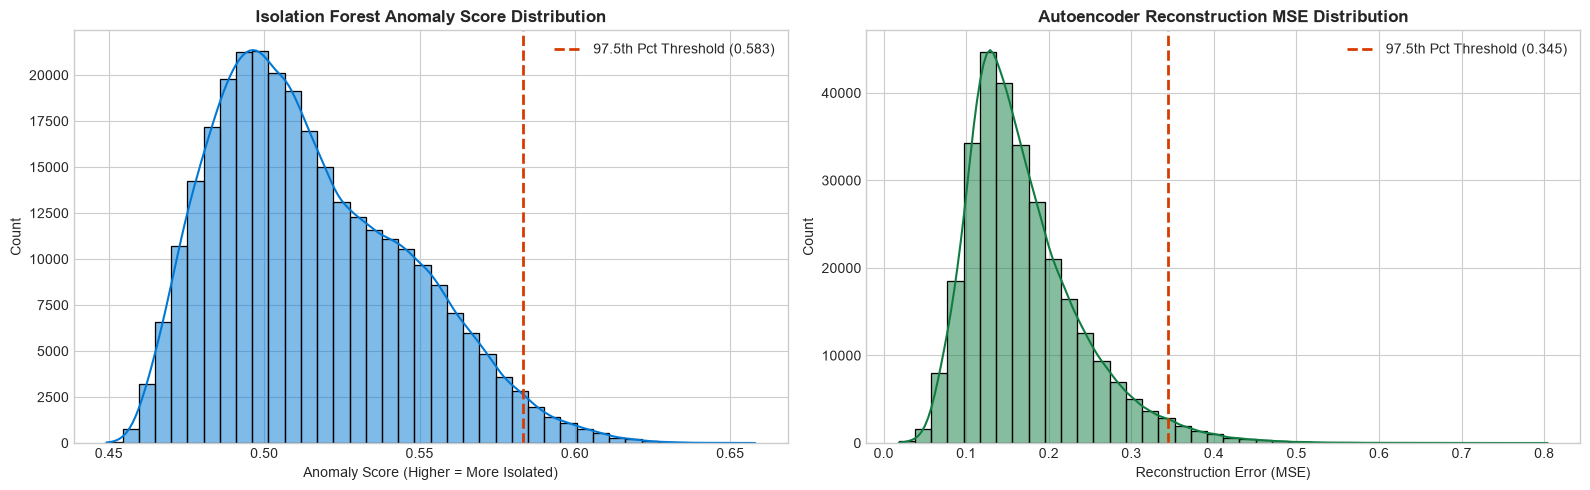

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Isolation Forest Score Distribution
sns.histplot(sessions['iso_anomaly_score'], bins=40, kde=True, color='#0078D4', ax=ax1)
iso_thresh = np.percentile(sessions['iso_anomaly_score'], 97.5)
ax1.axvline(iso_thresh, color='#D83B01', linestyle='--', linewidth=2, label=f'97.5th Pct Threshold ({iso_thresh:.3f})')
ax1.set_title('Isolation Forest Anomaly Score Distribution', fontsize=12, fontweight='bold')
ax1.set_xlabel('Anomaly Score (Higher = More Isolated)', fontsize=10)
ax1.legend()

# Autoencoder Reconstruction Error Distribution
sns.histplot(sessions['ae_recon_error'], bins=40, kde=True, color='#107C41', ax=ax2)
ax2.axvline(ae_threshold, color='#D83B01', linestyle='--', linewidth=2, label=f'97.5th Pct Threshold ({ae_threshold:.3f})')
ax2.set_title('Autoencoder Reconstruction MSE Distribution', fontsize=12, fontweight='bold')
ax2.set_xlabel('Reconstruction Error (MSE)', fontsize=10)
ax2.legend()

plt.tight_layout()
plt.show()


## 8. Deep-Dive Anomaly Investigation & Categorization

We dissect the highest-scoring anomalous sessions to identify recurring behavioral signatures:
1. **Power Utilization Disparities**: Sessions where charging power is unusually low relative to the charger rating.
2. **Pricing & Cost Extremes**: Sessions with tariffs near the £0.80 ceiling or £0.45 floor.
3. **Charger-Type Disparities**: Distribution of anomalies across DC_50kW, DC_150kW, and DC_300kW.
4. **Station-Level Disproportionality**: Identifying whether specific stations experience elevated anomaly rates.


In [10]:
# Charger Type Anomaly Breakdown
chg_anomaly_summary = sessions.groupby('charger_type').agg(
    total_sessions=('session_id', 'count'),
    if_anomalies=('flag_isolation_forest', 'sum'),
    ae_anomalies=('flag_autoencoder', 'sum'),
    consensus_anomalies=('consensus_flags', lambda x: (x >= 2).sum())
).reset_index()
chg_anomaly_summary['if_rate_pct'] = (chg_anomaly_summary['if_anomalies'] / chg_anomaly_summary['total_sessions']) * 100
chg_anomaly_summary['ae_rate_pct'] = (chg_anomaly_summary['ae_anomalies'] / chg_anomaly_summary['total_sessions']) * 100
chg_anomaly_summary['consensus_rate_pct'] = (chg_anomaly_summary['consensus_anomalies'] / chg_anomaly_summary['total_sessions']) * 100

print("--- ANOMALY RATES BY CHARGER TYPE ---")
display(chg_anomaly_summary.round(2))

# User Type Anomaly Breakdown
usr_anomaly_summary = sessions.groupby('user_type').agg(
    total_sessions=('session_id', 'count'),
    if_anomalies=('flag_isolation_forest', 'sum'),
    ae_anomalies=('flag_autoencoder', 'sum'),
    consensus_anomalies=('consensus_flags', lambda x: (x >= 2).sum())
).reset_index()
usr_anomaly_summary['if_rate_pct'] = (usr_anomaly_summary['if_anomalies'] / usr_anomaly_summary['total_sessions']) * 100
usr_anomaly_summary['ae_rate_pct'] = (usr_anomaly_summary['ae_anomalies'] / usr_anomaly_summary['total_sessions']) * 100
usr_anomaly_summary['consensus_rate_pct'] = (usr_anomaly_summary['consensus_anomalies'] / usr_anomaly_summary['total_sessions']) * 100

print("--- ANOMALY RATES BY USER TYPE ---")
display(usr_anomaly_summary.round(2))

# Station Level Summary
stn_anomaly_summary = sessions.groupby(['station_id', 'station_region']).agg(
    total_sessions=('session_id', 'count'),
    if_anomalies=('flag_isolation_forest', 'sum'),
    ae_anomalies=('flag_autoencoder', 'sum'),
    consensus_anomalies=('consensus_flags', lambda x: (x >= 2).sum()),
    mean_duration=('session_duration_minutes', 'mean'),
    mean_energy=('energy_kwh', 'mean'),
    mean_power=('avg_power_kw', 'mean')
).reset_index()
stn_anomaly_summary['consensus_rate_pct'] = (stn_anomaly_summary['consensus_anomalies'] / stn_anomaly_summary['total_sessions']) * 100
stn_anomaly_summary = stn_anomaly_summary.sort_values('consensus_rate_pct', ascending=False)

print("--- TOP 5 STATIONS BY ANOMALY RATE ---")
display(stn_anomaly_summary.head(5).round(2))


--- ANOMALY RATES BY CHARGER TYPE ---
  charger_type  total_sessions  ...  ae_rate_pct  consensus_rate_pct
0     DC_150kW           96977  ...         2.18                0.06
1     DC_300kW           60226  ...         3.76                6.82
2      DC_50kW          136821  ...         2.17                0.05

[3 rows x 8 columns]
--- ANOMALY RATES BY USER TYPE ---
  user_type  total_sessions  ...  ae_rate_pct  consensus_rate_pct
0  delivery           73339  ...         2.40                1.26
1     fleet           73696  ...         3.62                1.25
2    public           73754  ...         1.83                2.02
3      taxi           73235  ...         2.15                1.24

[4 rows x 8 columns]
--- TOP 5 STATIONS BY ANOMALY RATE ---
   station_id station_region  ...  mean_power  consensus_rate_pct
1     STN_002         London  ...      171.52                4.50
11    STN_012     South West  ...      149.72                3.55
7     STN_008       Midlands  ...      1

In [11]:
# Extract Top 20 Most Extreme Consensus Anomalies
top_anomalies = sessions.sort_values(['consensus_flags', 'iso_anomaly_score'], ascending=[False, False]).head(20)[
    ['session_id', 'station_id', 'charger_type', 'max_power_kW', 'user_type',
     'start_timestamp', 'session_duration_minutes', 'energy_kwh', 'avg_power_kw',
     'power_utilization_ratio', 'price_per_kwh', 'total_cost', 'iso_anomaly_score', 'ae_recon_error', 'consensus_flags']
]

print("--- TOP 10 HIGHEST-SCORING UNUSUAL CHARGING SESSIONS ---")
display(top_anomalies.head(10).round(2))


--- TOP 10 HIGHEST-SCORING UNUSUAL CHARGING SESSIONS ---
        session_id station_id  ... ae_recon_error  consensus_flags
117214  S_00117215    STN_008  ...           0.45                4
141843  S_00141844    STN_018  ...           0.42                4
42847   S_00042848    STN_007  ...           0.36                4
54246   S_00054247    STN_006  ...           0.40                4
41668   S_00041669    STN_007  ...           0.38                4
118586  S_00118587    STN_007  ...           0.36                4
95586   S_00095587    STN_017  ...           0.35                4
46778   S_00046779    STN_008  ...           0.38                4
235874  S_00235875    STN_031  ...           0.07                3
49813   S_00049814    STN_012  ...           0.24                3

[10 rows x 15 columns]


## 9. Business Implications & Operational Triage Workflow

How an EV charging operator can operationalize these anomaly detection models:

### 1. Alert Triage & Tiered Investigation Queue
- **Tier 1 (Consensus Anomaly, Score >= 3)**: Immediate high-priority queue. Sessions exhibiting both high isolation and high reconstruction error represent severe physical or commercial deviations.
- **Tier 2 (Model Divergence, Score = 2)**: Secondary review queue (e.g. Autoencoder flagged low power utilization while Isolation Forest flagged pricing).
- **Tier 3 (Single Model Flag, Score = 1)**: Informational telemetry monitoring; no manual intervention required.

### 2. Operational Value Levers:
- **Preventing Hardware Damage & Thermal Throttling**: Flagging sustained charging stalls or unexpected power drops on 300kW chargers before complete hardware failure occurs.
- **Revenue Protection**: Detecting pricing discrepancies, billing formula rounding errors, and unmetered session leakages.
- **Customer Experience & Bay Clearance**: Identifying slow-charging vehicles occupying ultra-rapid bays, informing future idle fee and dynamic pricing policies.


In [12]:
out_dir = os.path.join('analysis')
os.makedirs(out_dir, exist_ok=True)

# 1. Export Model Comparison
model_comparison_df.to_csv(os.path.join(out_dir, 'model_comparison.csv'), index=False)

# 2. Export Station Anomaly Summary
stn_anomaly_summary.to_csv(os.path.join(out_dir, 'station_anomaly_summary.csv'), index=False)

# 3. Export Overall Anomaly Summary (Aggregated by Charger & User Type)
anomaly_summary_df = pd.concat([
    chg_anomaly_summary.assign(dimension='charger_type').rename(columns={'charger_type': 'segment'}),
    usr_anomaly_summary.assign(dimension='user_type').rename(columns={'user_type': 'segment'})
], ignore_index=True)
anomaly_summary_df.to_csv(os.path.join(out_dir, 'anomaly_summary.csv'), index=False)

# 4. Export Top Flagged Anomaly Investigation Records (Top 1,000 extreme sessions)
top_flagged_export = sessions[sessions['consensus_flags'] >= 2].sort_values('iso_anomaly_score', ascending=False).head(1000)[
    ['session_id', 'station_id', 'station_region', 'charger_id', 'charger_type', 'max_power_kW',
     'user_type', 'start_timestamp', 'session_duration_minutes', 'energy_kwh', 'avg_power_kw',
     'power_utilization_ratio', 'price_per_kwh', 'total_cost', 'cost_per_minute',
     'flag_iqr', 'flag_zscore', 'flag_isolation_forest', 'flag_autoencoder', 'consensus_flags',
     'iso_anomaly_score', 'ae_recon_error']
]
top_flagged_export.to_csv(os.path.join(out_dir, 'anomaly_detection_results.csv'), index=False)

print("Successfully exported all 4 Analysis 11 CSV deliverables:")
print(" - model_comparison.csv")
print(" - station_anomaly_summary.csv")
print(" - anomaly_summary.csv")
print(" - anomaly_detection_results.csv")


Successfully exported all 4 Analysis 11 CSV deliverables:
 - model_comparison.csv
 - station_anomaly_summary.csv
 - anomaly_summary.csv
 - anomaly_detection_results.csv


## 10. Analytical Limitations & Conclusion

### Limitations:
1. **Unsupervised Setting**: No confirmed ground-truth labels for fraud, meter failures, or vehicle faults exist in the dataset. Models detect statistical rarity, not verified malfeasance.
2. **Vehicle Telemetry Absence**: Without vehicle battery State of Charge (SoC), ambient temperature, or battery capacity, thermal throttling by the vehicle's onboard BMS cannot be distinguished from charging dispenser power limitations.
3. **Threshold Sensitivity**: The 2.5% contamination rate was selected as a realistic operational queue capacity benchmark, but can be dynamically tuned based on operator staffing levels.

### Conclusion:
Analysis 11 successfully delivers an unsupervised anomaly detection framework combining statistical benchmarks, Isolation Forest, and an MLP Neural Autoencoder. The multi-model consensus approach successfully isolates extreme power stalls, dwell bottlenecks, and pricing outliers across the network, providing an automated foundation for condition-based maintenance and revenue assurance.
